# Evals Visualisation

Run the eval suite and chart the results.

In [9]:
import sys
from pathlib import Path

try:
    _root = Path(__file__).resolve().parents[1]
except NameError:
    _root = Path.cwd().parents[0]
    if str(_root) not in sys.path:
        sys.path.insert(0, str(_root))
if str(_root / "evals") not in sys.path:
    sys.path.insert(0, str(_root / "evals"))
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import pandas as pd

# Jupyter uses a different event loop; nest-asyncio patch avoids errors.
import nest_asyncio
nest_asyncio.apply()

matplotlib.rcParams.update({
    "font.size": 12,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "figure.dpi": 120,
    "figure.figsize": (10, 6),
})

def _fmt_ms(ms: int) -> str:
    if ms >= 60_000:
        return f"{ms / 60_000:.1f}m"
    return f"{ms / 1000:.0f}s"

def _build_df(results):
    """Convert a list of EvalResult into a pandas DataFrame."""
    return pd.DataFrame([vars(r) for r in results])

def _case_label(case_id: str) -> str:
    """Short label: strip leading zeros."""
    parts = case_id.split("_", 1)
    return parts[-1] if len(parts) > 1 else case_id

## Run evals

Import `run_suite` from the harness runner, execute the cases, and build a 
summary DataFrame for charting.

In [10]:
from runner import run_suite, EvalResult

output_dir = _root / "runs" / "eval-output"
output_dir.mkdir(parents=True, exist_ok=True)

# ── config ────────────────────────────────────────────────────────────────
model = "Qwen3.6-35B-A3B-4bit"
base_url = "http://192.168.178.102:11434/v1"

# Run all cases (pass a list like ["01", "03"] for a subset).
results: list[EvalResult] = run_suite(case_ids=None, output_dir=output_dir,
                                       model=model, base_url=base_url)

df = _build_df(results)
df["label"] = df["case_id"].apply(_case_label)
df["passed_display"] = df["passed"].map({True: "✓", False: "✗"})
df["time_human"] = df["wall_time_ms"].apply(_fmt_ms)

print("=== Results ===")
for _, r in df.iterrows():
    status = f"[{r['status']}]"
    print(f"  {r['passed_display']}  {r['case_id']}  {status}  "
          f"steps={r['total_steps']}  time={r['time_human']}  tokens={r['total_tokens']}")

passed = df["passed"].sum()
total = len(df)
print(f"\nPass rate: {passed}/{total} ({passed / total * 100:.0f}%)")

[01_create_hello] Running...


NotFoundError: Error code: 404 - {'detail': 'Not Found'}

## Charts

### Pass / Fail Overview

Bar chart showing per-case pass/fail with status.

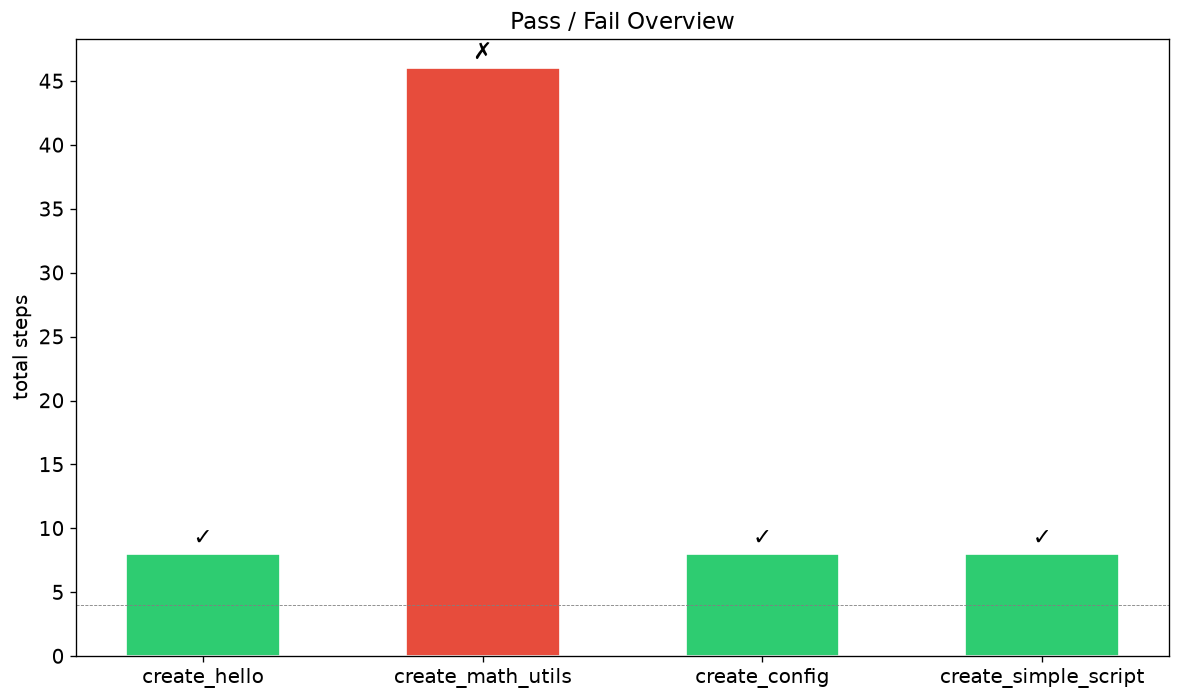

In [ ]:
fig, ax = plt.subplots()

colors = ["#2ecc71" if p else "#e74c3c" for p in df["passed"]]
ax.bar(df["label"], df["total_steps"], color=colors, edgecolor="white", width=0.55)

# annotate with pass/fail
for i, row in df.iterrows():
    ax.annotate(row["passed_display"],
                (i, row["total_steps"] + 0.3), ha="center", va="bottom", fontsize=14)

ax.set_ylabel("total steps")
ax.set_title("Pass / Fail Overview")
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
ax.axhline(len(df), color="grey", linewidth=0.5, linestyle="--")  # not used, placeholder
fig.tight_layout()

### Plan vs Build Steps

Stacked horizontal bar showing plan and build step breakdown.

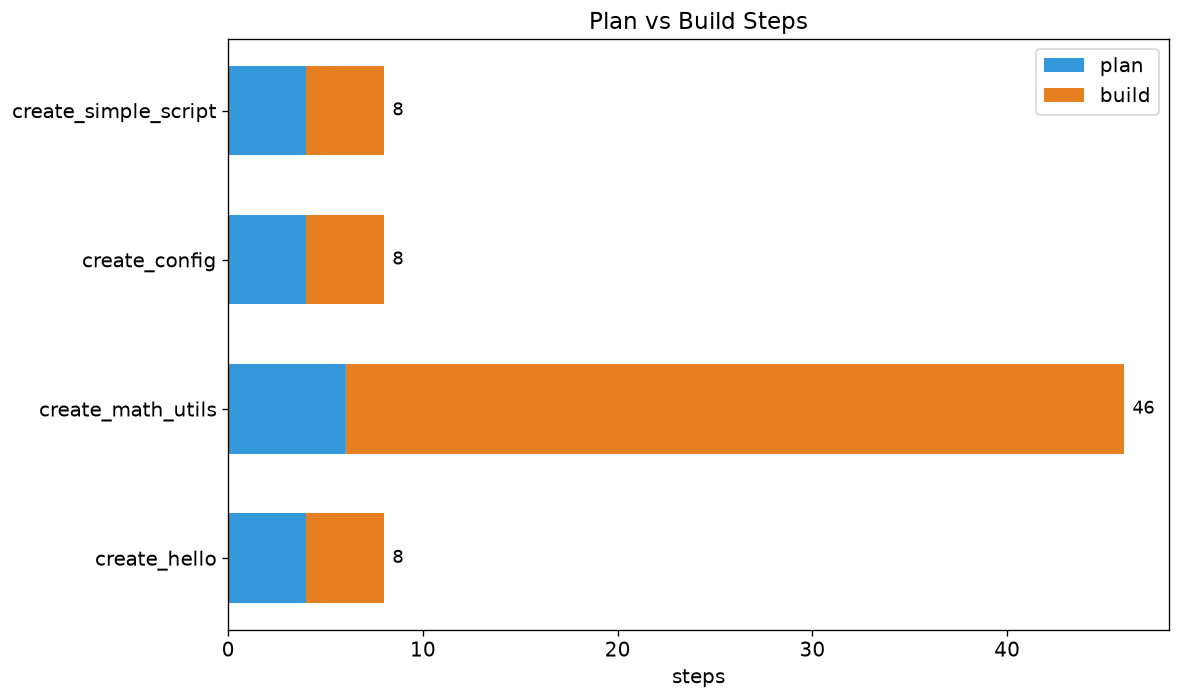

In [ ]:
fig, ax = plt.subplots()

idx = range(len(df))
plan  = df["plan_steps"].values
build = df["build_steps"].values

ax.barh(idx, plan,  color="#3498db", label="plan",  height=0.6)
ax.barh(idx, build, color="#e67e22", left=plan, label="build", height=0.6)

for i, (_, row) in enumerate(df.iterrows()):
    ax.annotate(f"{int(row['total_steps'])}",
                (row['total_steps'], i),
                xytext=(5, 0), textcoords="offset points",
                va="center", fontsize=11)

ax.set_yticks(idx)
ax.set_yticklabels(df["label"])
ax.set_xlabel("steps")
ax.set_title("Plan vs Build Steps")
ax.legend()
fig.tight_layout()

### Wall Time

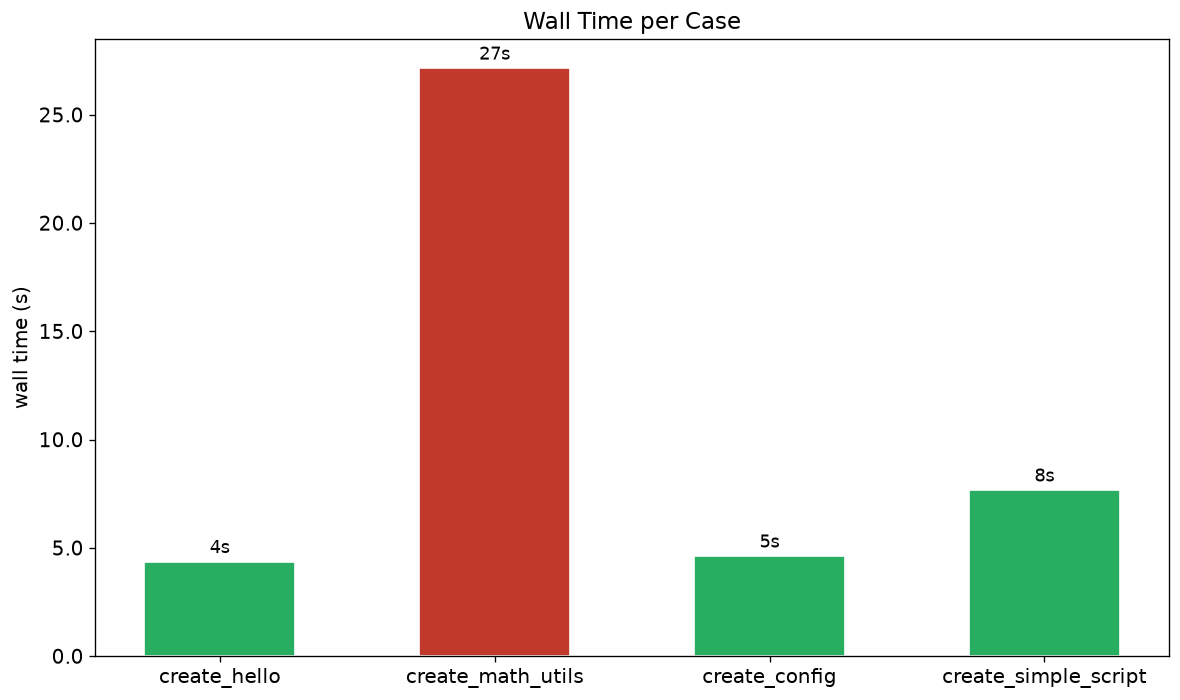

In [ ]:
fig, ax = plt.subplots()

colors = ["#27ae60" if p else "#c0392b" for p in df["passed"]]
bars = ax.bar(df["label"], df["wall_time_ms"] / 1000, color=colors,
              edgecolor="white", width=0.55)

for bar, row in zip(bars, df.iterrows()):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.2,
            row[1]["time_human"], ha="center", va="bottom", fontsize=11)

ax.set_ylabel("wall time (s)")
ax.set_title("Wall Time per Case")
ax.yaxis.set_major_formatter(mticker.FormatStrFormatter("%.1f"))
fig.tight_layout()

### Total Tokens

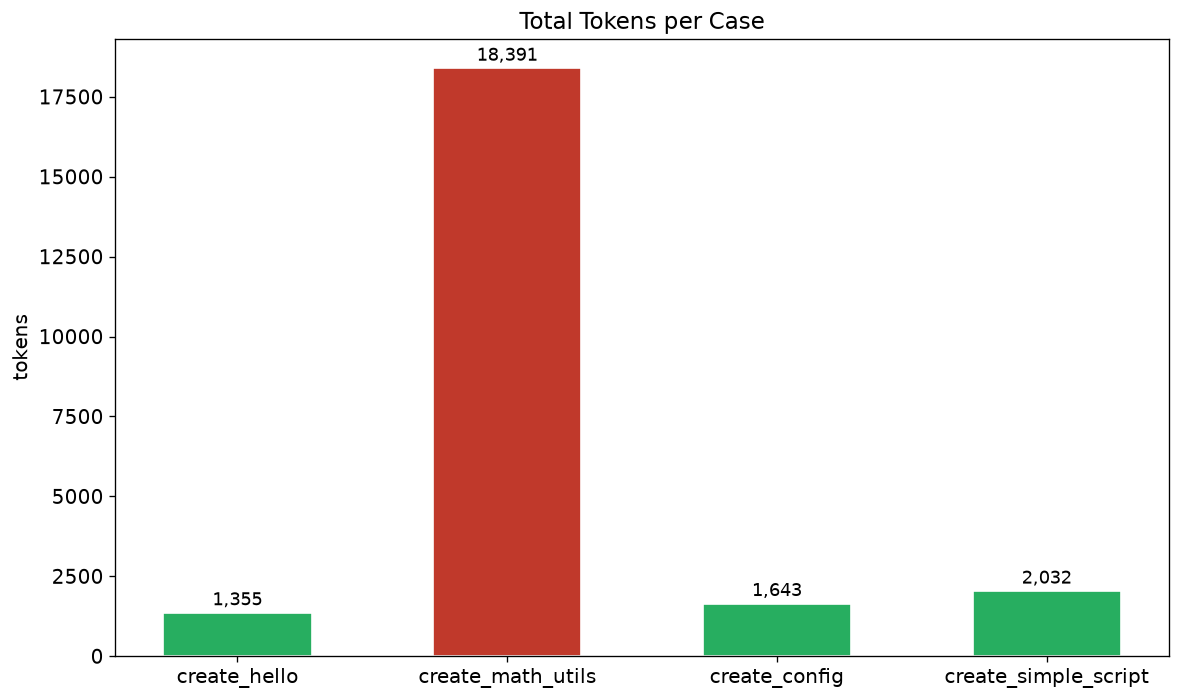

In [ ]:
fig, ax = plt.subplots()

colors = ["#27ae60" if p else "#c0392b" for p in df["passed"]]
bars = ax.bar(df["label"], df["total_tokens"], color=colors,
              edgecolor="white", width=0.55)

for bar, row in zip(bars, df.iterrows()):
    label = f"{int(row[1]['total_tokens']):,}"
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 100,
            label, ha="center", va="bottom", fontsize=11)

ax.set_ylabel("tokens")
ax.set_title("Total Tokens per Case")
fig.tight_layout()

### Summary Table

Readable DataFrame of all results.

In [ ]:
display_cols = ["case_id", "passed_display", "status", "plan_steps",
                "build_steps", "total_steps", "time_human", "total_tokens"]
df[display_cols]

,case_id,passed_display,status,plan_steps,build_steps,total_steps,time_human,total_tokens
0,01_create_hello,✓,ok,4,4,8,4s,1355
1,02_create_math_utils,✗,max_steps,6,40,46,27s,18391
2,03_create_config,✓,ok,4,4,8,5s,1643
3,04_create_simple_script,✓,ok,4,4,8,8s,2032


### Summary Stats

In [ ]:
summary = {
    "total_cases": len(df),
    "passed": int(df["passed"].sum()),
    "fail_rate": f"{(1 - df['passed'].mean()) * 100:.0f}%",
    "mean_total_steps": f"{df['total_steps'].mean():.1f}",
    "mean_wall_time": df["wall_time_ms"].mean(),
    "total_tokens": f"{int(df['total_tokens'].sum()):,}",
}
pd.DataFrame([summary]).T.rename(columns={0: ""})

,
total_cases,4
passed,3
fail_rate,25%
mean_total_steps,17.5
mean_wall_time,10945.25
total_tokens,"23,421"
